<a href="https://colab.research.google.com/github/ayishathanha53-eng/AI-ML-lab/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv('titanic.csv')

display(df.head())
display(df.info())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None

In [ ]:
# --- Full Data Preprocessing and Model Training ---

# Reload the dataset to ensure a clean start for preprocessing
df_processed = pd.read_csv('titanic.csv')

# Handle missing values
df_processed['Age'] = df_processed['Age'].fillna(df_processed['Age'].median())
df_processed['Embarked'] = df_processed['Embarked'].fillna(df_processed['Embarked'].mode()[0])

# Drop columns that are not useful for the model or have too many missing values
df_processed.drop(['Cabin', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)

# Convert categorical features to numerical using one-hot encoding
df_processed = pd.get_dummies(df_processed, columns=['Sex', 'Embarked'], drop_first=True)

print("Preprocessed DataFrame Info:")
display(df_processed.info())
display(df_processed.head())

# Define features (X) and target (y) from the processed DataFrame
X = df_processed.drop('Survived', axis=1)
y = df_processed['Survived']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Logistic Regression model
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"\nAccuracy: {accuracy:.4f}")
print("Classification Report:\n", report)
print("Confusion Matrix:\n", conf_matrix)


Preprocessed DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Age         891 non-null    float64
 3   SibSp       891 non-null    int64  
 4   Parch       891 non-null    int64  
 5   Fare        891 non-null    float64
 6   Sex_male    891 non-null    bool   
 7   Embarked_Q  891 non-null    bool   
 8   Embarked_S  891 non-null    bool   
dtypes: bool(3), float64(2), int64(4)
memory usage: 44.5 KB


None

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True



Accuracy: 0.8101
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179

Confusion Matrix:
 [[90 15]
 [19 55]]


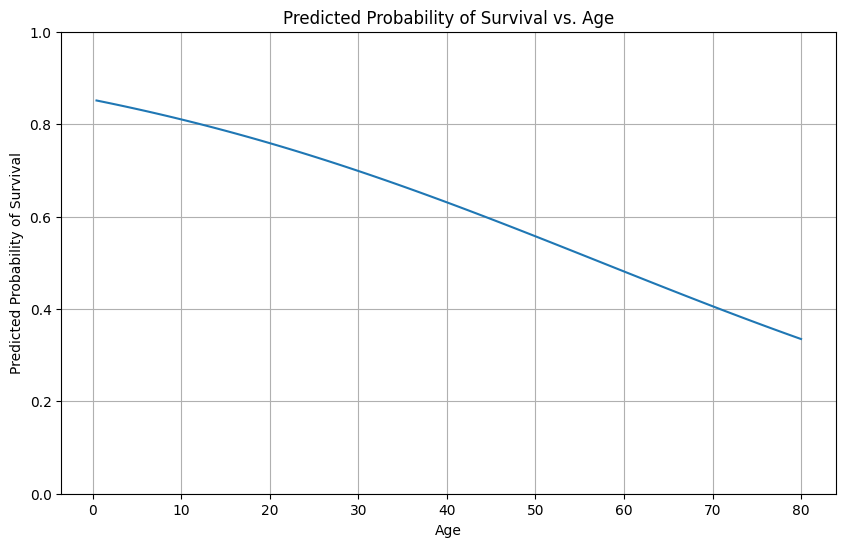

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Prepare data for plotting predicted probabilities against Age
# Create a DataFrame with a range of 'Age' values, keeping other features at their median
age_range = np.linspace(df_processed['Age'].min(), df_processed['Age'].max(), 100)

# Create a DataFrame initialized with 'Age' and then fill other columns appropriately
dummy_df = pd.DataFrame({'Age': age_range})

# Add other columns from X_train, filling with median/mode values
for col in X_train.columns:
    if col != 'Age': # Age is already handled
        if X_train[col].dtype == 'bool':
            # For boolean (one-hot encoded) columns, set to False (0) for a neutral baseline
            dummy_df[col] = False
        else:
            # For other numerical features, use their median and fill for all rows
            dummy_df[col] = X_train[col].median()

# Ensure the columns are in the same order as X_train for prediction
dummy_df = dummy_df[X_train.columns]

# Predict probabilities
# model.predict_proba returns probabilities for both classes (0 and 1). We want the probability of class 1 (Survived)
predicted_probabilities = model.predict_proba(dummy_df)[:, 1]

# Plotting the predicted probabilities vs. Age
plt.figure(figsize=(10, 6))
sns.lineplot(x=age_range, y=predicted_probabilities)
plt.title('Predicted Probability of Survival vs. Age')
plt.xlabel('Age')
plt.ylabel('Predicted Probability of Survival')
plt.grid(True)
plt.ylim(0, 1) # Probabilities are between 0 and 1
plt.show()

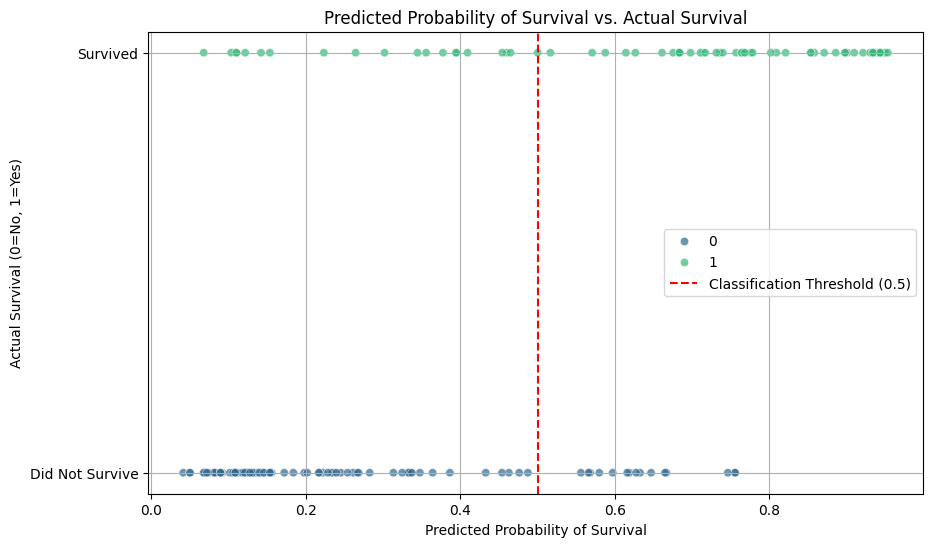

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get predicted probabilities for the positive class (Survived=1) on the test set
y_proba_test = model.predict_proba(X_test)[:, 1]

# Create a DataFrame for plotting
plot_df = pd.DataFrame({
    'Actual Survival': y_test,
    'Predicted Probability of Survival': y_proba_test
})

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Predicted Probability of Survival', y='Actual Survival', data=plot_df, hue='Actual Survival', palette='viridis', alpha=0.7)
plt.axvline(x=0.5, color='r', linestyle='--', label='Classification Threshold (0.5)') # Add a vertical line at the decision boundary
plt.title('Predicted Probability of Survival vs. Actual Survival')
plt.xlabel('Predicted Probability of Survival')
plt.ylabel('Actual Survival (0=No, 1=Yes)')
plt.yticks([0, 1], ['Did Not Survive', 'Survived'])
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# ============================================================
# PREDICT SURVIVAL FOR A NEW PASSENGER
# ============================================================

print("\n--- New Passenger Prediction ---")

# Get passenger information from the user
pclass = int(input("Enter passenger class (1, 2, or 3): "))
sex = input("Enter sex (male/female): ").strip().lower()
age = float(input("Enter age: "))
sibsp = int(input("Enter number of siblings/spouses aboard: "))
parch = int(input("Enter number of parents/children aboard: "))
fare = float(input("Enter fare: "))
embarked = input("Enter port of embarkation (C/Q/S): ").strip().upper()

# Create a dictionary with the new passenger's data
new_passenger = {
    'Pclass': pclass,
    'Age': age,
    'SibSp': sibsp,
    'Parch': parch,
    'Fare': fare,
    'Sex_male': 1 if sex == 'male' else 0,
    'Embarked_Q': 1 if embarked == 'Q' else 0,
    'Embarked_S': 1 if embarked == 'S' else 0
}

# Convert to DataFrame
new_passenger_df = pd.DataFrame([new_passenger])

# Make sure columns are in exactly the same order as training data
new_passenger_df = new_passenger_df[X_train.columns]

# Predict survival
prediction = model.predict(new_passenger_df)[0]

# Get probability
probability = model.predict_proba(new_passenger_df)[0]

# Display result
print("\n--- Prediction Result ---")

if prediction == 1:
    print("Prediction: The passenger is likely to SURVIVE.")
else:
    print("Prediction: The passenger is likely to NOT SURVIVE.")

print(f"Probability of survival: {probability[1] * 100:.2f}%")
print(f"Probability of not surviving: {probability[0] * 100:.2f}%")



--- New Passenger Prediction ---
Enter passenger class (1, 2, or 3): 1
Enter sex (male/female): male
Enter age: 23
Enter number of siblings/spouses aboard: 0
Enter number of parents/children aboard: 0
Enter fare: 80
Enter port of embarkation (C/Q/S): q

--- Prediction Result ---
Prediction: The passenger is likely to SURVIVE.
Probability of survival: 59.70%
Probability of not surviving: 40.30%


In [ ]:
!pip install -q gradio



In [ ]:
import gradio as gr
import pandas as pd

def predict_survival(pclass, sex, age, sibsp, parch, fare, embarked):

    # Convert inputs to correct types
    pclass = int(pclass)
    age = float(age)
    sibsp = int(sibsp)
    parch = int(parch)
    fare = float(fare)

    # Create passenger data
    passenger = pd.DataFrame({
        'Pclass': [pclass],
        'Age': [age],
        'SibSp': [sibsp],
        'Parch': [parch],
        'Fare': [fare],
        'Sex_male': [1 if sex == 'male' else 0],
        'Embarked_Q': [1 if embarked == 'Q' else 0],
        'Embarked_S': [1 if embarked == 'S' else 0]
    })

    # Make sure columns are in exactly the same order
    passenger = passenger[X_train.columns]

    # Prediction
    prediction = model.predict(passenger)[0]

    # Probability
    probability = model.predict_proba(passenger)[0]

    survival_probability = probability[1] * 100
    death_probability = probability[0] * 100

    if prediction == 1:
        result = "🟢 Passenger is likely to SURVIVE"
    else:
        result = "🔴 Passenger is likely to NOT SURVIVE"

    return (
        result,
        f"Survival Probability: {survival_probability:.2f}%",
        f"Not Surviving Probability: {death_probability:.2f}%"
    )


# Create UI
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # 🚢 Titanic Survival Prediction
        ### Logistic Regression Model
        Enter passenger details to predict survival.
        """
    )

    with gr.Row():

        with gr.Column():

            pclass = gr.Dropdown(
                choices=[1, 2, 3],
                value=3,
                label="Passenger Class"
            )

            sex = gr.Dropdown(
                choices=["male", "female"],
                value="male",
                label="Sex"
            )

            age = gr.Number(
                value=30,
                label="Age"
            )

            sibsp = gr.Number(
                value=0,
                label="Siblings / Spouses"
            )

        with gr.Column():

            parch = gr.Number(
                value=0,
                label="Parents / Children"
            )

            fare = gr.Number(
                value=32.0,
                label="Fare"
            )

            embarked = gr.Dropdown(
                choices=["C", "Q", "S"],
                value="S",
                label="Port of Embarkation"
            )

    predict_button = gr.Button(
        "🔮 Predict Survival",
        variant="primary"
    )

    result = gr.Textbox(
        label="Prediction",
        interactive=False
    )

    survival_probability = gr.Textbox(
        label="Survival Probability",
        interactive=False
    )

    death_probability = gr.Textbox(
        label="Not Surviving Probability",
        interactive=False
    )

    predict_button.click(
        fn=predict_survival,
        inputs=[
            pclass,
            sex,
            age,
            sibsp,
            parch,
            fare,
            embarked
        ],
        outputs=[
            result,
            survival_probability,
            death_probability
        ]
    )

demo.launch(share=True)


/tmp/ipykernel_765/613993034.py:50: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://81eaf7dfac97c3f9fa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
